# Regression Primer — Guided Practice

In the data-exploration primer, you described associations in house-sale records.
Here you will use some of those records to **learn a prediction rule** and assess
how well it works for houses the model was not trained on.

**Question:** how well can we predict a historical sale price from information
about a house?

By the end, you should be able to:

- identify input features and a numerical prediction target;
- fit and interpret a simple linear regression;
- compare predictions with a simple baseline on held-out records;
- investigate model complexity and recognise possible overfitting;
- choose a small model using validation results, then assess it on a final test set.


## How to work through this notebook

Complete Exercises 1–4 in order. Study each **worked example**, then write
your own code in the **Your turn** cells. These usually contain only a comment.
The instructions state the goal and the object names needed by later cells;
you choose the intermediate steps and variable names.

Complete each task before running its **checkpoint**. A checkpoint stops
with an explanation while required work is missing. After finishing all core
tasks, restart the kernel and run all cells to check reproducibility.

Keep the supplied sample and partitions fixed. Fit using training data,
choose using validation data, and use the test data for the final assessment.
Predictions written before an experiment need not be correct. Extensions
are optional. Optional syntax hints can be opened after trying a task.

## Setup — familiar data, a new question

Keep **`kc_house_data.csv` beside this notebook**. In Google Colab, upload the
CSV into the session's files. Use a Python environment with `pandas`, `numpy`,
`matplotlib`, and `scikit-learn` installed. The package is imported as `sklearn`.

We reuse the King County sale records from 2014–2015. Prices are historical
amounts in **USD**, and `sqft_living` is living area in **square feet**.
A price is a numerical target, so this is a **regression** problem.

Some properties were sold more than once. The supplied preparation keeps the
earliest recorded sale for each `id`, then draws a reproducible random sample
of **1,000 different houses**. This prevents repeated sales of one house from
appearing on both sides of a split. Keeping one sale is a modelling choice,
not a claim that the other sales are errors. The small sample keeps experiments
quick and makes the limits of the resulting scores important. **You may also try to use the full dataset later**

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

possible_paths = [Path("kc_house_data.csv"), Path("Primer Assignments") / "kc_house_data.csv"]
data_path = next((path for path in possible_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Put kc_house_data.csv beside this notebook, then run this cell again.")

houses = pd.read_csv(data_path)
unique_houses = houses.sort_values("date").drop_duplicates(subset="id", keep="first")
#Change 1000 with len(unique_houses) to use the full dataset of unique houses
number_of_houses = 1000
modelling_data = unique_houses.sample(n=number_of_houses, random_state=44).copy()

print("Sale records in the CSV:", len(houses))
print("Different houses in the modelling sample:", modelling_data["id"].nunique())
modelling_data[["id", "sqft_living", "price"]].head()

Sale records in the CSV: 21613
Different houses in the modelling sample: 1000


,id,sqft_living,price
3412,3971700940,1430,330000.0
3582,1925069006,530,355000.0
14103,6817800330,1090,405000.0
13128,5710500230,1900,545000.0
3587,1787600164,1560,310000.0


### Three groups with different jobs

| Group | Share | What we use it for |
|---|---|---|
| Training | 60% | Learn coefficients and any preprocessing settings. |
| Validation | 20% | Compare models and choose features or polynomial degree. |
| Test | 20% | Assess the chosen approach after those decisions are made. |

The supplied split first sets aside 20% for testing, then takes a quarter of
the remaining 80% for validation: 0.25 × 0.80 = 0.20 of the original sample.
`random_state` fixes the random allocation so comparisons can use the same houses.

**Keep the test set aside until the final assessment in Exercise 4.** Repeatedly
using its scores to choose a model would make it part of model selection.
This random split asks about other houses from a similar historical setting;
it does not demonstrate that the model forecasts prices in future years.

In [13]:
development_data, test_data = train_test_split(
    modelling_data, test_size=0.20, random_state=44
)
train_data, validation_data = train_test_split(
    development_data, test_size=0.25, random_state=44
)

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Test records reserved for the final assessment:", len(test_data))

# Supplied checks: a house must not appear in more than one group.
assert set(train_data["id"]).isdisjoint(validation_data["id"])
assert set(train_data["id"]).isdisjoint(test_data["id"])
assert set(validation_data["id"]).isdisjoint(test_data["id"])

Training records: 600
Validation records: 200
Test records reserved for the final assessment: 200


## Exercise 1 — Learn and interpret a straight-line model

A **feature** is information supplied to a model; the **target** is the value
we want it to predict. Start with one feature, living area, and target price.

In scikit-learn, `X` is a table with one column per feature, while `y` contains
one target value per row. Double brackets keep `X` as a two-dimensional table;
single brackets select the one-dimensional target column.

In [14]:
X_train = train_data[["sqft_living"]]
y_train = train_data["price"]
X_validation = validation_data[["sqft_living"]]
y_validation = validation_data["price"]

print("Training feature-table shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Training living-area range:", X_train["sqft_living"].min(), "to", X_train["sqft_living"].max())

Training feature-table shape: (600, 1)
Training target shape: (600,)
Training living-area range: 580 to 7440


**Worked example — fitting.** Simple linear regression learns a rule of the form

**predicted price = intercept + slope × living area**.

`.fit(X_train, y_train)` learns the intercept and slope by minimising the sum
of squared training errors. `.predict(...)` applies the fitted rule to inputs.
Fitting is the learning step; predicting does not learn new coefficients.

Before running the example, predict the sign of the slope. What association
from the previous primer supports your prediction?

_Your prediction:_ I predict a positive slope. In the previous, sqrt_living and price showed a positive association: larger homes tended to sell for more, and the scatterplot trended upward.

In [15]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print(f"Intercept: USD {linear_model.intercept_:,.2f}")
print(f"Slope: USD {linear_model.coef_[0]:,.2f} per additional square foot")

Intercept: USD -75,978.57
Slope: USD 299.72 per additional square foot


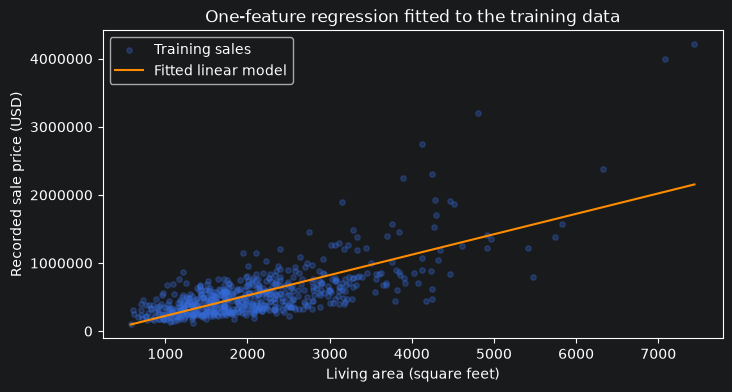

In [16]:
# An increasing grid gives a smooth line, rather than joining unsorted houses.
area_grid = pd.DataFrame({
    "sqft_living": np.linspace(X_train["sqft_living"].min(), X_train["sqft_living"].max(), 200)
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_train["sqft_living"], y_train, s=15, alpha=0.3, label="Training sales")
ax.plot(area_grid["sqft_living"], linear_model.predict(area_grid), color="darkorange", label="Fitted linear model")
ax.set_xlabel("Living area (square feet)")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("One-feature regression fitted to the training data")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.show()

**Your turn — construct inputs and use the rule.** Write complete code to
create a DataFrame named **new_houses** with a **sqft_living** column containing
1,500 and 2,500 square feet, in that order. Obtain **predicted_prices** using
the fitted linear_model. Display the areas and predicted prices together.

Use the same feature-column name as during fitting. The worked plot shows
an example of constructing a prediction input table.

In [17]:
# Your code: construct the input table, predict, and display the results.
new_houses = pd.DataFrame({"sqft_living": [1500, 2500]})
predicted_prices = linear_model.predict(new_houses)

answer = new_houses.copy()
answer["predicted_price"] = predicted_prices
print(answer)

   sqft_living  predicted_price
0         1500    373596.239369
1         2500    673312.779821


In [18]:
assert "new_houses" in globals() and "predicted_prices" in globals(), "Create new_houses and predicted_prices first."
assert list(new_houses.columns) == ["sqft_living"], "Check the input column name."
assert new_houses["sqft_living"].tolist() == [1500, 2500], "Use the two requested areas, in order."
assert np.asarray(predicted_prices).shape == (2,) and np.isfinite(predicted_prices).all(), "Produce two finite predictions."
print("Checkpoint passed: two input rows and two predictions are ready.")

Checkpoint passed: two input rows and two predictions are ready.


**Interpret:** According to this model, how much does predicted price change
for an additional **100 square feet**? Show how the units lead to your answer.

_Your answer:_  The slope is the predicted change in price per additional square foot, so its units are USD per square foot. For an additional 100 square feet:

100 sqft × (USD 299.72 / sqft) = USD 29,972

The square feet cancel and leave USD. So, according to this model, an additional 100 square feet is associated with a predicted price that is about USD 29,972 higher. This holds anywhere along the fitted line, because a linear model assumes a constant change per square foot.

**Question the rule:** What price would the intercept assign to zero living
area? Why is that not a useful valuation? Does the fitted slope establish that
extending a particular house would cause its price to change by that amount?

_Your answer:_ At zero living area, the model predicts the intercept itself: USD −75,978.57. This is not a useful valuation because a negative price is impossible, and no house in the data has zero living area; the smallest training house is much larger. Zero lies outside the observed range, so this is extrapolation.
The intercept is mainly a term that positions the line correctly within the range of the data, not a meaningful price

**Your turn — fit another one-feature model.** Predict price using
**only bathrooms**. Select its training inputs and price target, create
a new LinearRegression named **bathroom_model**, and fit it.
Print its intercept and slope with meaningful units.

Then construct a training scatterplot and add its fitted line using an
increasing input grid, with labels, a title, and a legend. Use the
living-area worked example as a reference and write this implementation
yourself. Keep linear_model, X_train, and y_train unchanged.

Intercept: USD -69,000.74
Slope: USD 291,017.46 per additional bathroom


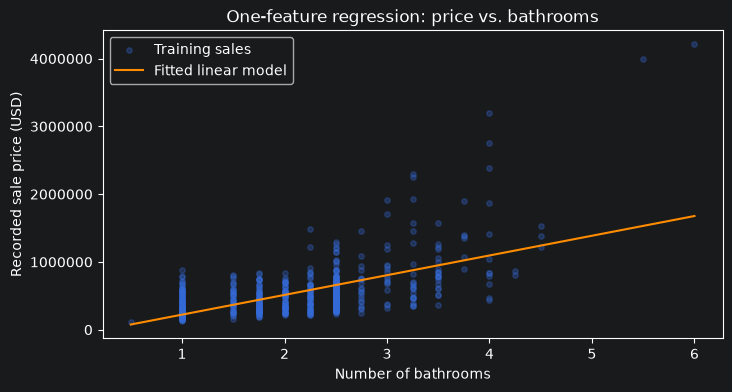

In [19]:
# Your code: prepare inputs, create and fit bathroom_model, report coefficients, and plot.
# Inputs and target for the bathroom-only model (new names keep X_train / y_train unchanged)
X_train_bath = train_data[["bathrooms"]]   # double brackets -> DataFrame with one column
y_train_bath = train_data["price"]

bathroom_model = LinearRegression()
bathroom_model.fit(X_train_bath, y_train_bath)

print(f"Intercept: USD {bathroom_model.intercept_:,.2f}")
print(f"Slope: USD {bathroom_model.coef_[0]:,.2f} per additional bathroom")

# Increasing input grid so the fitted line is drawn smoothly
bathroom_grid = pd.DataFrame({
    "bathrooms": np.linspace(X_train_bath["bathrooms"].min(), X_train_bath["bathrooms"].max(), 200)
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_train_bath["bathrooms"], y_train_bath, s=15, alpha=0.3, label="Training sales")
ax.plot(bathroom_grid["bathrooms"], bathroom_model.predict(bathroom_grid),
        color="darkorange", label="Fitted linear model")
ax.set_xlabel("Number of bathrooms")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("One-feature regression: price vs. bathrooms")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.show()

In [20]:
assert "bathroom_model" in globals(), "Create bathroom_model before continuing."
assert hasattr(bathroom_model, "coef_"), "Fit the new model on training records."
assert list(bathroom_model.feature_names_in_) == ["bathrooms"], "Use a DataFrame containing only bathrooms."
print("Checkpoint passed: the fitted bathroom model has the intended input.")

Checkpoint passed: the fitted bathroom model has the intended input.


**Interpret the units:** What are the units of this model's slope?
Would a numerically larger slope than the living-area slope establish
that bathrooms are a more useful predictor? Explain.

_Your answer:_ The slope is measured in USD per additional bathroom (USD / bathroom), because the target is price in USD and the feature counts bathrooms. According to this model, each additional bathroom is associated with a predicted price about USD 291,017.46 higher.

and No, a numerically larger slope than the living-area slope (USD 299.72 per square foot) would not establish that bathrooms are a more useful predictor. The two slopes have different units and refer to steps of very different size: one extra bathroom is a large change in a house, while one extra square foot is tiny.

## Exercise 2 — Assess predictions on held-out houses

A line can fit its training data and still make poor predictions elsewhere.
We will compare it with a **baseline** that predicts the mean training price
for every house. A useful model should offer evidence of improvement over
that simple rule on the same validation records. Because the groups contain
different houses, validation RMSE can be lower than training RMSE; it is not
guaranteed to be higher. Compare competing models on the same validation group.

**RMSE**, the root mean squared error, is the square root of the mean squared
prediction error. Here it is in **USD**; lower is better. Squaring gives large
errors more influence. RMSE is not a guarantee that every prediction falls
within that amount of the true price. MSE, before taking the square root,
would have units of USD squared.

We also report **R²**: 1 means perfect predictions; 0 matches a constant equal
to the mean target in the group being evaluated; negative values are possible.
**R² is not a percentage of houses predicted correctly.** Our baseline uses
the training mean, so its validation R² need not be exactly zero.

The supplied `rmse` function packages the square-root calculation; you may
call it without rewriting its definition.

In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

def rmse(actual, predicted):
    return float(np.sqrt(mean_squared_error(actual, predicted)))

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_train_rmse = rmse(y_train, baseline.predict(X_train))
baseline_validation_predictions = baseline.predict(X_validation)
baseline_validation_rmse = rmse(y_validation, baseline_validation_predictions)

print(f"Baseline predicts the training mean: USD {y_train.mean():,.2f}")
print(f"Training RMSE: USD {baseline_train_rmse:,.2f}")
print(f"Validation RMSE: USD {baseline_validation_rmse:,.2f}")
print(f"Validation R²: {r2_score(y_validation, baseline_validation_predictions):.3f}")

Baseline predicts the training mean: USD 555,474.23
Training RMSE: USD 400,614.34
Validation RMSE: USD 313,057.22
Validation R²: -0.019


**Your turn — implement evaluation and assemble a table.** Using the already
fitted linear_model, write code to obtain **linear_validation_predictions**,
**linear_train_rmse**, **linear_validation_rmse**, and **linear_validation_r2**.

Construct and display a DataFrame named **linear_results** comparing the
baseline with the living-area model. Include training and validation RMSE
for each, with readable column labels and units.

Also calculate and print **bathroom_validation_rmse**, using your fitted
bathroom_model and the corresponding validation input column.

Use the supplied rmse function and r2_score. Pair each prediction with the
actual price for the same rows in the same order. Do not refit on validation
data or use a plotting grid as a set of actual target values.

<details>
<summary>Optional table-construction hint</summary>

A list of dictionaries can become a table with pd.DataFrame(rows).
Each dictionary supplies one row, with its keys naming the columns.

</details>

In [22]:
# Your code: predict, calculate all scores, construct linear_results, and display your comparisons.
# Living-area model: predictions on validation inputs (no refitting)
linear_validation_predictions = linear_model.predict(X_validation)

# Scores, each prediction paired with the actual price for the same rows
linear_train_rmse = rmse(y_train, linear_model.predict(X_train))
linear_validation_rmse = rmse(y_validation, linear_validation_predictions)
linear_validation_r2 = r2_score(y_validation, linear_validation_predictions)

# Comparison table: one dictionary per row
rows = [
    {
        "Model": "Baseline (training mean)",
        "Training RMSE (USD)": baseline_train_rmse,
        "Validation RMSE (USD)": baseline_validation_rmse,
        "Validation R²": r2_score(y_validation, baseline_validation_predictions),
    },
    {
        "Model": "Linear model (living area)",
        "Training RMSE (USD)": linear_train_rmse,
        "Validation RMSE (USD)": linear_validation_rmse,
        "Validation R²": linear_validation_r2,
    },
]
linear_results = pd.DataFrame(rows)
display(linear_results.style.format({
    "Training RMSE (USD)": "{:,.2f}",
    "Validation RMSE (USD)": "{:,.2f}",
    "Validation R²": "{:.3f}",
}))

# Bathroom model: validation inputs must be a DataFrame with the same column name used in fitting
bathroom_validation_rmse = rmse(y_validation, bathroom_model.predict(validation_data[["bathrooms"]]))
print(f"Bathroom model validation RMSE: USD {bathroom_validation_rmse:,.2f}")

,Model,Training RMSE (USD),Validation RMSE (USD),Validation R²
0,Baseline (training mean),"400,614.34","313,057.22",-0.019
1,Linear model (living area),"276,218.36","231,472.72",0.443


Bathroom model validation RMSE: USD 264,093.16


In [31]:
required = ["linear_validation_predictions", "linear_train_rmse", "linear_validation_rmse", "linear_validation_r2", "linear_results", "bathroom_validation_rmse"]
assert all(name in globals() for name in required), "Complete the predictions, scores, and comparison table first."
assert np.asarray(linear_validation_predictions).shape == y_validation.shape, "Check which rows you predicted."
assert np.allclose(linear_validation_predictions, linear_model.predict(X_validation)), "Use the fitted living-area model on validation inputs."
assert np.isclose(linear_train_rmse, rmse(y_train, linear_model.predict(X_train))), "Check training RMSE and units."
assert np.isclose(linear_validation_rmse, rmse(y_validation, linear_validation_predictions)), "Check validation RMSE and units."
assert np.isclose(linear_validation_r2, r2_score(y_validation, linear_validation_predictions)), "Check validation R²."
assert np.isclose(bathroom_validation_rmse, rmse(y_validation, bathroom_model.predict(validation_data[["bathrooms"]]))), "Check the bathroom model's validation score."
assert isinstance(linear_results, pd.DataFrame) and len(linear_results) == 2, "Create a two-row comparison table."
print("Checkpoint passed: the scores use the intended rows and target units.")

Checkpoint passed: the scores use the intended rows and target units.


**Your turn — calculate and plot residuals.** A residual is **actual price
minus predicted price**. A positive residual means the model underestimated
that sale price.

Compute the living-area model's validation residuals as **linear_residuals**.
Construct a scatterplot with predicted prices on the horizontal axis and
residuals on the vertical axis. Add a horizontal zero line, a title, and
labels with units. A zero line can be added with ax.axhline(0, ...).
Build the calculation and plot yourself using the familiar plotting pattern.

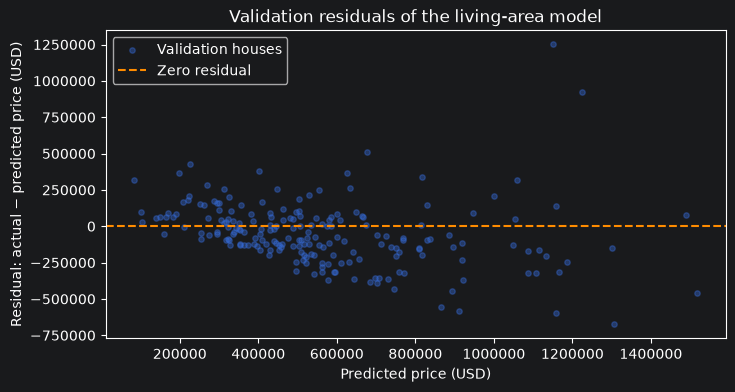

In [32]:
# Your code: calculate linear_residuals and construct the diagnostic plot.

# Residual = actual price minus predicted price (same validation rows, same order)
linear_residuals = y_validation - linear_validation_predictions

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(linear_validation_predictions, linear_residuals, s=15, alpha=0.4, label="Validation houses")
ax.axhline(0, color="darkorange", linestyle="--", label="Zero residual")
ax.set_xlabel("Predicted price (USD)")
ax.set_ylabel("Residual: actual − predicted price (USD)")
ax.set_title("Validation residuals of the living-area model")
ax.ticklabel_format(style="plain", axis="both")
ax.legend()
plt.show()

**Compare:** Does the linear model improve on the baseline's validation RMSE?
Quote both values. Would a small training RMSE alone answer that question?

_Your answer:_ Yes. The linear model’s validation RMSE is USD 231,472.72, lower than the baseline’s USD 313,057.22, so living area helps predict prices of unseen houses. A small training RMSE alone would not answer this, because it only measures errors on houses the model was fitted to, not on new ones.

**Inspect:** Describe one feature of the validation residuals. Do you see
systematic patterns, large misses, or a changing spread? State what a positive
residual means and one limitation of using living area alone.

_Your answer:_ The residuals are not evenly spread: the spread grows for higher predicted prices, and there are a few large positive residuals, meaning some expensive houses were strongly underestimated. A positive residual means actual price minus predicted price is above zero, i.e. the model underestimated the price. One limitation of using living area alone is that it ignores other factors like location and quality, so two houses of the same size can have very different prices.

**Compare one-feature models:** Which validation RMSE is lower, the living-area
model's or the bathroom model's? Quote both values and explain why this is a more
useful comparison than their raw slope magnitudes.

_Your answer:_

## Exercise 3 — Investigate polynomial complexity

A straight line may miss curvature. A degree-2 polynomial adds a squared
input; higher degrees add more powers. The degree is a **hyperparameter**:
a setting we choose, unlike coefficients learned by `.fit()`.

**Worked example — a pipeline.** `make_pipeline` connects three steps:
`StandardScaler` centres and scales the living-area input, `PolynomialFeatures`
constructs its powers, and `LinearRegression` learns coefficients. Scaling
before taking powers reduces problems caused by very large raw numbers such
as square footage raised to the eighth power.

The whole pipeline uses the same `.fit()` and `.predict()` interface as our
first model. Fit it on **training data only**. It then reuses that scaling
when predicting validation inputs; do not fit a second scaler on validation data.

Degree-2 validation RMSE: USD 222,035.85


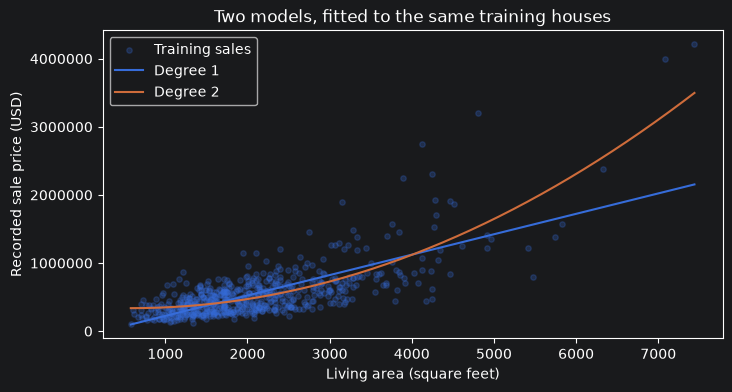

In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

quadratic_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression(),
)
quadratic_model.fit(X_train, y_train)
print(f"Degree-2 validation RMSE: USD {rmse(y_validation, quadratic_model.predict(X_validation)):,.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(X_train["sqft_living"], y_train, s=15, alpha=0.25, label="Training sales")
ax.plot(area_grid["sqft_living"], linear_model.predict(area_grid), label="Degree 1")
ax.plot(area_grid["sqft_living"], quadratic_model.predict(area_grid), label="Degree 2")
ax.set_xlabel("Living area (square feet)")
ax.set_ylabel("Recorded sale price (USD)")
ax.set_title("Two models, fitted to the same training houses")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.show()

**Your turn — write the full experiment.** Using the degree-2 worked example
as a reference, write a loop comparing polynomial degrees **1 to 8**.

For each degree, create a **fresh pipeline**, fit on the original X_train and
y_train, predict both training and validation groups, and calculate RMSE.
Use the same data groups each time.

Produce **polynomial_models**, a dictionary mapping each degree to its fitted
pipeline, and **polynomial_results**, a list of eight dictionaries containing
degree, training_rmse, and validation_rmse.
Write the model construction, fitting, scoring, and result storage yourself.
Keep the original feature tables unchanged.

<details>
<summary>Optional loop and storage hints</summary>

for degree in range(1, 9): repeats an indented block eight times.
Start a dictionary with {} and a list with [].
mapping[key] = value stores an item; rows.append(record) adds a record.
The worked example shows the pipeline components and their order.

</details>

In [34]:
# Your code: initialise the result containers and implement the complete degree experiment.
polynomial_models = {}     # degree -> fitted pipeline
polynomial_results = []    # one dictionary per degree

for degree in range(1, 9):
    # Fresh pipeline each time, so no degree reuses anything fitted before
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    )
    model.fit(X_train, y_train)   # learn only from training houses

    train_predictions = model.predict(X_train)
    validation_predictions = model.predict(X_validation)

    polynomial_models[degree] = model
    polynomial_results.append({
        "degree": degree,
        "training_rmse": rmse(y_train, train_predictions),
        "validation_rmse": rmse(y_validation, validation_predictions),
    })

**Your turn — organise and plot the experiment.** Turn polynomial_results into
a DataFrame named **polynomial_table**, sort by degree, and display it.
Plot training and validation RMSE against degree on the same axes, including
markers, a legend, a title, and labels with units.

This compares model performance rather than drawing fitted price curves.
Build both the table and the plot yourself.

,degree,training_rmse,validation_rmse
0,1,276218.36,231472.72
1,2,250557.04,222035.85
2,3,247065.51,221075.72
3,4,245708.70,219273.13
4,5,243132.14,217228.57
5,6,243124.20,217263.44
6,7,239999.79,217837.32
7,8,238439.19,217175.36


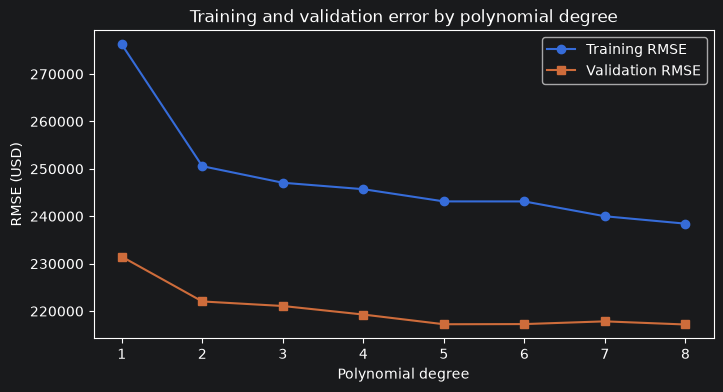

In [35]:
# Your code: construct polynomial_table and plot the two error curves.

# one row per degree, sorted by degree
polynomial_table = pd.DataFrame(polynomial_results).sort_values("degree").reset_index(drop=True)
display(polynomial_table.round(2))   # plain display, no .style, so jinja2 is not needed

# both error curves on the same axes
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(polynomial_table["degree"], polynomial_table["training_rmse"], marker="o", label="Training RMSE")
ax.plot(polynomial_table["degree"], polynomial_table["validation_rmse"], marker="s", label="Validation RMSE")
ax.set_xlabel("Polynomial degree")
ax.set_ylabel("RMSE (USD)")
ax.set_title("Training and validation error by polynomial degree")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.show()

**Your turn — make a validation-based choice.** Read the table and plot, then
choose `selected_degree`. The smallest validation RMSE is a useful starting
point; choosing a simpler degree with a very similar error can also be justified.
A tiny score difference on one small validation set is weak evidence that a more
complex model is reliably better.

**Overfitting** means fitting training-specific details that do not generalise
well. Look for a falling training error without a corresponding validation
improvement. Do not assume the plot must show a perfect U-shape.

In [39]:
# Your code: assign selected_degree from validation evidence and explain it below.
selected_degree = 2

# I selected degree 2. Its validation RMSE is USD 222,035.85, an improvement over the straight line - USD 231,472.72. Higher degrees improve validation only slightly: degree 5 reaches USD 217,228.57, and the lowest value, USD 217,175.36 at degree 8,
# is only about USD 53 better than degree 5. Such small differences on a small validation set are weak evidence of a reliably better model, so I prefer the simplest model that captures the main gain.
# So the highest degree does give the numerically lowest validation RMSE here, but not in a way that justifies its extra complexity.


**Interpret the experiment:** Is there evidence of overfitting on this split?
Explain from the table or plot. Why would choosing the smallest training error,
or repeatedly changing the split until a model wins, be misleading?

_Your answer:_ There is a mild sign of overfitting. From degree 5 to 8, the training RMSE keeps going down (USD 243,132 to USD 238,439), but the validation RMSE stays almost the same (USD 217,229 to USD 217,175). So the model fits the training houses better, but it does not predict new houses better. Choosing the smallest training error would be misleading, because a more complex model always fits its own training data better.

## Exercise 4 — Add information, choose a model, and assess it

**Your turn — implement a multiple-feature model.** Keep sqft_living and add
**one or two** features from bathrooms, bedrooms, sqft_lot, and yr_built.
These record bathroom count, bedroom count, lot area in square feet, and
construction year. Choose them for a reason.

Construct **feature_columns** and a new LinearRegression named **multi_model**.
Select its training data, fit it, and obtain **multi_validation_predictions**.
Calculate **multi_validation_rmse** and **multi_validation_r2**.
Create and display a labelled coefficient table or Series.
Organise the whole implementation yourself using the patterns practised earlier.

Use the fixed groups and leave the test set aside. Do not use raw numeric ZIP
codes or IDs as measurements. You are not required to beat a particular score.

**Before fitting:** justify your extra features and explain whether their
values would be available before knowing the sale price.

_Your reasoning:_ I kept sqft_living and added bathrooms and yr_built. Bathrooms may capture the quality and standard of a house beyond its size, and bathrooms alone already improved on the baseline in the earlier comparison. Year built adds different information, the age of the house, which is less overlapping with living area than bedrooms would be.

In [36]:
# Your code: select features, create and fit multi_model, evaluate it, and display labelled coefficients.

feature_columns = ["sqft_living", "bathrooms", "yr_built"]

# New variable names, so X_train and y_train stays unchanged
X_train_multi = train_data[feature_columns]
X_validation_multi = validation_data[feature_columns]

multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train)   # learn from training houses only

multi_validation_predictions = multi_model.predict(X_validation_multi)
multi_validation_rmse = rmse(y_validation, multi_validation_predictions)
multi_validation_r2 = r2_score(y_validation, multi_validation_predictions)

print(f"Multiple-feature model validation RMSE: USD {multi_validation_rmse:,.2f}")
print(f"Multiple-feature model validation R²: {multi_validation_r2:.3f}")

# Labelled coefficients (USD change per unit of each feature, others held fixed)
coefficients = pd.Series(multi_model.coef_, index=feature_columns, name="Coefficient (USD per unit)")
display(coefficients.round(2).to_frame())
print(f"Intercept: USD {multi_model.intercept_:,.2f}")

Multiple-feature model validation RMSE: USD 223,372.86
Multiple-feature model validation R²: 0.481


,Coefficient (USD per unit)
sqft_living,260.50
bathrooms,108170.71
yr_built,-2835.43


Intercept: USD 5,366,981.11


In [37]:
assert all(name in globals() for name in ["feature_columns", "multi_model", "multi_validation_predictions", "multi_validation_rmse", "multi_validation_r2"]), "Complete the multiple-feature implementation first."
allowed = {"sqft_living", "bathrooms", "bedrooms", "sqft_lot", "yr_built"}
assert "sqft_living" in feature_columns and 2 <= len(feature_columns) <= 3, "Keep living area and add one or two features."
assert len(set(feature_columns)) == len(feature_columns) and set(feature_columns) <= allowed, "Check the feature list."
expected = multi_model.predict(validation_data[feature_columns])
assert np.asarray(multi_validation_predictions).shape == y_validation.shape, "Check the validation rows."
assert np.allclose(multi_validation_predictions, expected), "Use the same feature columns and their original order."
assert np.isclose(multi_validation_rmse, rmse(y_validation, expected)), "Check validation RMSE."
assert np.isclose(multi_validation_r2, r2_score(y_validation, expected)), "Check validation R²."
multi_results_ready = True
print("Checkpoint passed: the multiple-feature scores use the intended validation records.")

Checkpoint passed: the multiple-feature scores use the intended validation records.


**Your turn — build the decision table.** Construct and display a DataFrame
named **validation_comparison** for the four main approaches: baseline,
living-area linear, your selected polynomial, and your multiple-feature model.
Include a model description and validation RMSE with units.

Reuse existing results, including the selected-degree row of polynomial_table.
Build the table yourself. Compare the same validation houses and exclude test
scores. The bathroom-only model was a separate one-feature practice comparison;
the final selection below uses these four main approaches.

In [40]:
# Your code: assemble and display validation_comparison from the four existing validation results.

# Validation RMSE of the selected polynomial, taken from the existing polynomial_table
polynomial_validation_rmse = float(
    polynomial_table.loc[polynomial_table["degree"] == selected_degree, "validation_rmse"].iloc[0]
)

validation_comparison = pd.DataFrame([
    {"Model": "baseline",   "Description": "Mean training price for every house",
     "Validation RMSE (USD)": baseline_validation_rmse},
    {"Model": "linear",     "Description": "Straight line, living area only",
     "Validation RMSE (USD)": linear_validation_rmse},
    {"Model": "polynomial", "Description": f"Degree-{selected_degree} polynomial, living area only",
     "Validation RMSE (USD)": polynomial_validation_rmse},
    {"Model": "multiple",   "Description": "Linear model with " + ", ".join(feature_columns),
     "Validation RMSE (USD)": multi_validation_rmse},
])

display(validation_comparison.round({"Validation RMSE (USD)": 2}))

,Model,Description,Validation RMSE (USD)
0,baseline,Mean training price for every house,313057.22
1,linear,"Straight line, living area only",231472.72
2,polynomial,"Degree-2 polynomial, living area only",222035.85
3,multiple,"Linear model with sqft_living, bathrooms, yr_b...",223372.86


**Your turn — commit to an approach before testing.** Set `chosen_name` to
`"baseline"`, `"linear"`, `"polynomial"`, or `"multiple"`, using the validation
comparison and your preference for simplicity when performance is similar.

**Your decision:** name the approach and features, quote the relevant
validation RMSE, and explain your choice. Do this before the final test cell.

_Your answer:_ I choose the polynomial approach: a degree-2 polynomial using only living area. Its validation RMSE is USD 222,035.85, the lowest of the four models. The multiple-feature model is almost the same (USD 223,372.86), the straight line is worse (USD 231,472.72), and the baseline is much worse (USD 313,057.22). Because the polynomial and the multiple-feature model are so close, I prefer the simpler one, which uses only one feature and also has the lowest error.

**A leakage check:** the previous primer calculated `price_per_sqft` from
`price` and `sqft_living`. Why would using `price_per_sqft` to predict an
unknown sale price be an unfair shortcut, even if it produced an excellent score?

_Your answer:_ price_per_sqft is calculated using the sale price (price divided by living area), so it already contains the answer we want to predict. A model could use it to get an almost perfect score without learning anything useful. For a house whose price is unknown, we could not calculate price_per_sqft, so this feature would not exist in real use.

In [42]:
# Your code: assign chosen_name after writing your validation-based decision.
chosen_name = "polynomial"

**Supplied final refit and assessment — a new workflow step.** After you choose
an approach, this code keeps its features and degree fixed, makes a fresh copy
with clone, fits on training **plus validation**, and evaluates on reserved test
houses. A mean baseline is refitted on the same combined records.
This new refitting step is provided; you will create the final plot yourself.

Do not change the model in response to test results and then report another
score on the same set as an independent final assessment.

In [43]:
from sklearn.base import clone

assert "validation_comparison" in globals() and "chosen_name" in globals(), "Complete your comparison table and model choice before testing."
choices = {
    "baseline": (baseline, ["sqft_living"]),
    "linear": (linear_model, ["sqft_living"]),
    "polynomial": (polynomial_models[selected_degree], ["sqft_living"]),
    "multiple": (multi_model, feature_columns),
}
assert chosen_name in choices, "Use one of the four stated choice names."
chosen_model, chosen_features = choices[chosen_name]
final_model = clone(chosen_model)
final_model.fit(development_data[chosen_features], development_data["price"])
final_predictions = final_model.predict(test_data[chosen_features])

final_baseline = DummyRegressor(strategy="mean")
final_baseline.fit(development_data[["sqft_living"]], development_data["price"])
test_baseline_predictions = final_baseline.predict(test_data[["sqft_living"]])
final_results = pd.DataFrame([
    {"Model": "Refitted mean baseline", "Test RMSE (USD)": rmse(test_data["price"], test_baseline_predictions), "Test R²": r2_score(test_data["price"], test_baseline_predictions)},
    {"Model": f"Chosen: {chosen_name}", "Test RMSE (USD)": rmse(test_data["price"], final_predictions), "Test R²": r2_score(test_data["price"], final_predictions)},
])
print("Final fit uses", len(development_data), "records; assessment uses", len(test_data), "test records.")
print(final_results.round(3).to_string(index=False))

Final fit uses 800 records; assessment uses 200 test records.
                 Model  Test RMSE (USD)  Test R²
Refitted mean baseline       274324.920   -0.006
    Chosen: polynomial       224671.923    0.325


**Your turn — visualise the final predictions.** Construct an actual-versus-
predicted scatterplot for the test houses: actual prices on the horizontal
axis, **final_predictions** on the vertical axis. Add a dashed diagonal
for perfect predictions, a title, and axis labels with units.

Choose a range covering both sets of prices. The diagonal joins points
with equal horizontal and vertical coordinates. Use this plot as evidence
in your reflection; do not use it to choose a different model.

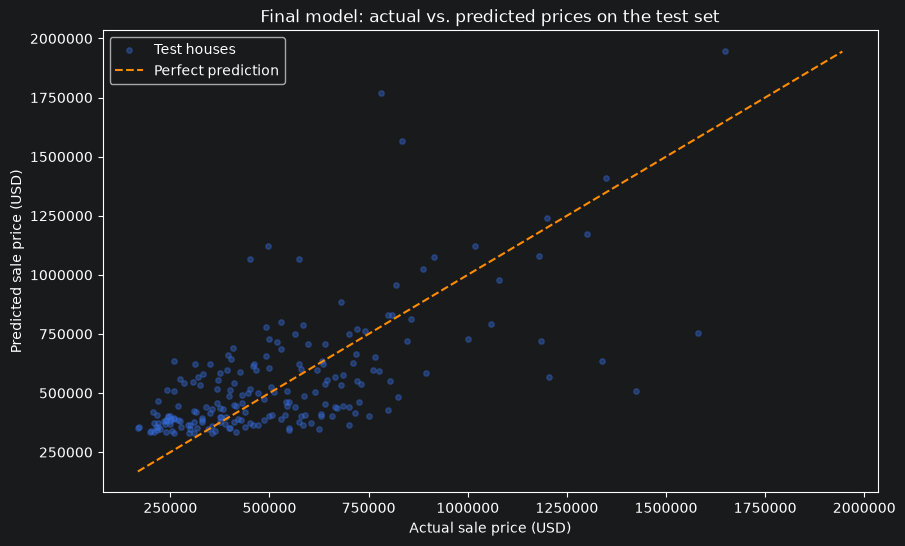

In [45]:
# Your code: plot actual and predicted test prices and add the perfect-prediction diagonal.

actual_test_prices = test_data["price"]

# Range covering both actual and predicted prices, so the diagonal spans the whole plot
low = min(actual_test_prices.min(), final_predictions.min())
high = max(actual_test_prices.max(), final_predictions.max())

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(actual_test_prices, final_predictions, s=15, alpha=0.4, label="Test houses")
ax.plot([low, high], [low, high], color="darkorange", linestyle="--", label="Perfect prediction")
ax.set_xlabel("Actual sale price (USD)")
ax.set_ylabel("Predicted sale price (USD)")
ax.set_title("Final model: actual vs. predicted prices on the test set")
ax.ticklabel_format(style="plain", axis="both")
ax.legend()
plt.show()

## Final reflection and submission

### Report
I chose a degree-2 polynomial regression using only living area. Its validation RMSE before refitting was USD 222,035.85. After refitting on the training plus validation data (800 houses), its test RMSE is USD 224,671.92 and its test R² is 0.325.
The refitted mean baseline has a test RMSE of USD 274,324.92 and R² of −0.006, so the chosen model improves on the baseline by about USD 49,653.
The validation and test estimates are close but not identical because they use different houses and the final fit uses more records.
R² here means the share of price variation explained by the model, not the percentage of houses predicted correctly.

---

### Reflect
More complexity helped only a little. Moving from a straight line to degree 2 lowered the validation RMSE from USD 231,472.72 to USD 222,035.85, and adding bathrooms and yr_built gave a similar result (USD 223,372.86).
From degree 5 onwards the validation error stopped improving while the training error kept falling, a mild sign of overfitting.

---

### Submission checklist

- Complete all core coding tasks, choices, and written answers; extensions are optional.
- Keep the supplied sample and partitions fixed, and run the supplied checkpoints.
- Explain prediction errors in the correct units; do not call R² an accuracy percentage.
- Make your model choice before running the final test assessment.
- Restart the kernel, run all cells, and save the notebook with your results.

Correct comparisons and thoughtful explanations matter more than beating a
particular score. Honest evidence that a model did not help is a valid finding.

## Optional extensions — choose one if you have time

### A. Reverse the prediction question

The original direction predicts **price from living area**. Now fit a separate
linear model predicting **living area from price**, using the same training
and validation houses. Use new variable names so the core experiment is unchanged.

**Your turn:** fit `reverse_model` on `train_data[["price"]]` and target
`train_data["sqft_living"]`, then evaluate its validation RMSE. Adapt the plot
from Exercise 1 with price on the horizontal axis and area on the vertical axis.
Label the RMSE in **square feet**, not USD.

Reversing the fitted prediction direction is not generally equivalent to
algebraically inverting the first line: least squares minimises errors in
the chosen target direction.

In [ ]:
# Optional: construct and fit the reverse model, evaluate area predictions, and plot its fitted rule.

**Your comparison:** what does the reversed model predict, and what is its
validation RMSE with units? Why would comparing that number directly with a
price-prediction RMSE not tell you which task is predicted more successfully?

_Your answer:_

### B. Explore predictions beyond the training range

**Worked experiment:** the inputs below lie outside the training living-area
range. Compare the linear model with the degree-8 polynomial from Exercise 3.
This is **extrapolation**. Predictions far from observed inputs can be unstable,
especially for flexible models; no actual prices are supplied for these examples.

In [ ]:
if 8 not in polynomial_models:
    print("INCOMPLETE: fit the polynomial models before trying this optional experiment.")
else:
    outside_houses = pd.DataFrame({
        "sqft_living": [0.5 * X_train["sqft_living"].min(), 1.5 * X_train["sqft_living"].max()]
    })
    outside_comparison = outside_houses.assign(
        linear_prediction_USD=linear_model.predict(outside_houses),
        degree_8_prediction_USD=polynomial_models[8].predict(outside_houses),
    )
    print("Observed training living-area range:", X_train["sqft_living"].min(), "to", X_train["sqft_living"].max())
    print(outside_comparison.round(2).to_string(index=False))

Describe the predictions and their plausibility. If the two models agree,
would that prove the predictions are reliable? Why can you not calculate an
actual prediction error for these two hypothetical houses from this table?

_Your answer:_

## Optional reference links

These explain the supplied tools; you do not need to read them all to complete the primer.

- [2026 course dataset](http://th-www.if.uj.edu.pl/~erichter/dydaktyka/Dydaktyka2026/DataScience-2026/kc_house_data.csv.zip)
- [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [Data leakage and consistent preprocessing](https://scikit-learn.org/stable/common_pitfalls.html)
- [Model selection and held-out evaluation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)